# 07 · Instruction savings, memory and ablations

The main results use 21 controlled correction scenarios per clip with fixed pairing across methods. The early-arrival advantage is shown separately from longer-delay and burst results. This notebook regenerates the publication figures and tables from the saved event-level measurements.

In [1]:
import json
import os
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "study.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from tinyml.config import DATASETS, SEEDS
from tinyml.folds import CLIP_DIR, FOLDS, model_dir, read_fixture
from tinyml.study_v2 import V2

REBUILD = os.getenv("TINYML_NOTEBOOK_REBUILD") == "1"
WORKERS = os.getenv("TINYML_NOTEBOOK_WORKERS", "3")
DATA = Path(os.getenv("TINYML_DATA_DIR", ROOT / "data")).resolve()
SCRATCH = ROOT / "build" / "notebooks_v2"

def run(*args):
    proc = subprocess.run([sys.executable, *map(str, args)], cwd=ROOT, capture_output=True, text=True)
    print(proc.stdout + proc.stderr, end="")
    proc.check_returncode()

print("Saved-result verification" if not REBUILD else "Rebuild and verification")

Saved-result verification


In [2]:
from tinyml.analysis_v2 import run as analyze

destination = SCRATCH / "figures"
report = analyze(V2, destination)
assert report["arm_mismatches"] == report["native_mismatches"] == 0
print(f"{report['arm_runs']:,} ARM runs across the two emulators.")
print(f"{report['native_streams']:,} native asynchronous replays.")
display(pd.DataFrame(report["per_dataset"]).T.round(2))

168,236 ARM runs across the two emulators.
2,025 native asynchronous replays.


,clips,subjects,all_vs_temporal_pct,all_vs_tap_pct,recent_vs_tap_pct,renode_recent_vs_tap_pct,recent_vs_recompute_pct,recent_vs_layer_replay_pct,recent_vs_tap_bootstrap_low_pct,recent_vs_tap_bootstrap_high_pct,optimized_build_append_change_pct,controlled_append_overhead_pct,controlled_break_even_repairs_per_100_appends,max_cache_sram_bytes,max_no_cache_sram_bytes,cache_policy_break_even_pct,int8_accuracy_pct
wisdm,162,51,43.00755,5.152349,40.90123,40.194279,40.504399,49.434737,40.522364,41.51335,-11.693909,0.521984,0.360249,7372,5322,"{'cache4': 0.0, 'cache8': 0.0, 'cache16': 0.0}",45.998765
mhealth,108,10,50.939985,13.126312,42.361047,42.41429,41.951166,56.726661,42.33555,42.400956,-11.8123,0.576455,0.398135,7528,5444,"{'cache4': 0.0, 'cache8': 0.0, 'cache16': 0.0}",56.728824


In [3]:
for name in ("table_01_main", "table_02_ablation", "table_03_cost", "table_04_sensitivity", "table_07_backends", "table_08_cache_policy"):
    display(Markdown((V2 / "tables" / (name + ".md")).read_text()))

Matched Unicorn Cortex-M4 repair costs. Saved is the average of nine fold/seed medians. Recent cases are last-observation-filled isolated samples.

| Dataset | Scenario | Reference | Saved (%) | Faster (%) | Pairs |
| --- | ---: | ---: | ---: | ---: | ---: |
| WISDM | All scenarios | replay | 43.0 | 95.5 | 10,206 |
| MHEALTH | All scenarios | replay | 50.9 | 98.5 | 6,804 |
| WISDM | Single, ages 0-7 | replay | 52.2 | 100.0 | 3,888 |
| MHEALTH | Single, ages 0-7 | replay | 59.2 | 100.0 | 2,592 |
| WISDM | All scenarios | tap_equal | 5.2 | 95.5 | 10,206 |
| MHEALTH | All scenarios | tap_equal | 13.1 | 98.5 | 6,804 |
| WISDM | Single, ages 0-7 | tap_equal | 40.9 | 99.9 | 3,888 |
| MHEALTH | Single, ages 0-7 | tap_equal | 42.4 | 100.0 | 2,592 |
| WISDM | All scenarios | recent_replay | 1.8 | 51.9 | 10,206 |
| MHEALTH | All scenarios | recent_replay | 9.6 | 55.0 | 6,804 |
| WISDM | Single, ages 0-7 | recent_replay | 40.5 | 88.7 | 3,888 |
| MHEALTH | Single, ages 0-7 | recent_replay | 42.0 | 95.0 | 2,592 |


Paired implementation ablations on the listed workload subsets. The CSV includes all fold and seed rows.

| Change | WISDM saved (%) | WISDM wins (%) | MHEALTH saved (%) | MHEALTH wins (%) |
| --- | ---: | ---: | ---: | ---: |
| Age-indexed masks | 0.06 | 91.4 | 0.08 | 96.8 |
| Recent single-update entry | 0.51 | 100.0 | 0.54 | 100.0 |
| Accumulator reuse | 40.08 | 91.0 | 42.18 | 91.1 |
| Recent accumulator dispatch | 0.78 | 100.0 | 0.84 | 100.0 |
| Full replay for three changed taps | 0.00 | 0.0 | 0.00 | 0.0 |
| Exact activation equality | 0.00 | 29.2 | 1.05 | 53.2 |
| Batch application | 60.65 | 95.1 | 51.60 | 100.0 |
| Cached fallback on older samples | -0.00 | 0.0 | -0.00 | 0.0 |


The optimized builds expose the combined effect of the cache and GCC code generation. The controlled build prevents convolution kernel inlining and cloning. Its amortized break-even uses the mean extra instructions per append divided by mean savings per recent repair. SRAM is live state plus the maximum correction stack in the optimized build.

| Dataset | Optimized append Δ (%) | Controlled append Δ (%) | Controlled break-even (%) | Cached (B) | Uncached (B) |
| --- | ---: | ---: | ---: | ---: | ---: |
| WISDM | -11.69 | +0.52 | 0.36 | 7,372 | 5,322 |
| MHEALTH | -11.81 | +0.58 | 0.40 | 7,528 | 5,444 |


Sensitivity uses one training seed per fold and at most one clip per participant. The zero-cache row compares the cache-free recent path with tap-mask equality.

| Dataset | Profile | Recent saved (%) | Accepted (%) | SRAM (B) |
| --- | ---: | ---: | ---: | ---: |
| WISDM | zero_cache | 0.62 | 100.0 | 5,322 |
| MHEALTH | zero_cache | 0.65 | 100.0 | 5,444 |
| WISDM | cache4 | 37.62 | 100.0 | 6,572 |
| MHEALTH | cache4 | 35.23 | 100.0 | 6,728 |
| WISDM | cache8 | 40.45 | 100.0 | 7,372 |
| MHEALTH | cache8 | 42.37 | 100.0 | 7,528 |
| WISDM | cache16 | 40.45 | 100.0 | 8,924 |
| MHEALTH | cache16 | 42.94 | 100.0 | 9,080 |
| WISDM | scalar | 45.22 | 100.0 | 7,360 |
| MHEALTH | scalar | 47.61 | 100.0 | 7,516 |
| WISDM | m33 | 39.55 | 100.0 | 7,372 |
| MHEALTH | m33 | 41.60 | 100.0 | 7,528 |
| WISDM | horizon8 | 41.17 | 60.0 | 3,972 |
| MHEALTH | horizon8 | 43.10 | 60.0 | 4,368 |
| WISDM | horizon24 | 40.51 | 86.7 | 5,332 |
| MHEALTH | horizon24 | 42.49 | 86.7 | 5,632 |
| WISDM | append8 | 41.66 | 100.0 | 7,348 |
| MHEALTH | append8 | 43.36 | 100.0 | 7,504 |


Identical ARM firmware in Unicorn and Renode. All score checks and SRAM watermarks agree. Instruction-count differences are relative to Renode. Both experiments retain their original counts.

| Dataset | Method | Matched | Median difference (%) | Max difference (%) |
| --- | ---: | ---: | ---: | ---: |
| WISDM | replay | 255 | 0.066 | 1.980 |
| WISDM | tap_equal | 255 | 0.066 | 1.980 |
| WISDM | recent_replay | 255 | 0.069 | 2.899 |
| WISDM | accumulator | 255 | 0.590 | 2.899 |
| MHEALTH | replay | 50 | 0.063 | 0.990 |
| MHEALTH | tap_equal | 50 | 0.062 | 0.990 |
| MHEALTH | recent_replay | 50 | 0.066 | 1.449 |
| MHEALTH | accumulator | 50 | 0.731 | 1.449 |


Amortized cost across separately optimized cache builds. Appends include any compiler code-generation differences.

| Dataset | Cache | Append change (inst.) | Break-even (%) | SRAM (B) |
| --- | ---: | ---: | ---: | ---: |
| WISDM | cache4 | -2444.0 | 0.00 | 6,572 |
| MHEALTH | cache4 | -2355.0 | 0.00 | 6,728 |
| WISDM | cache8 | -2444.0 | 0.00 | 7,372 |
| MHEALTH | cache8 | -2355.0 | 0.00 | 7,528 |
| WISDM | cache16 | -2444.0 | 0.00 | 8,924 |
| MHEALTH | cache16 | -2355.0 | 0.00 | 9,080 |


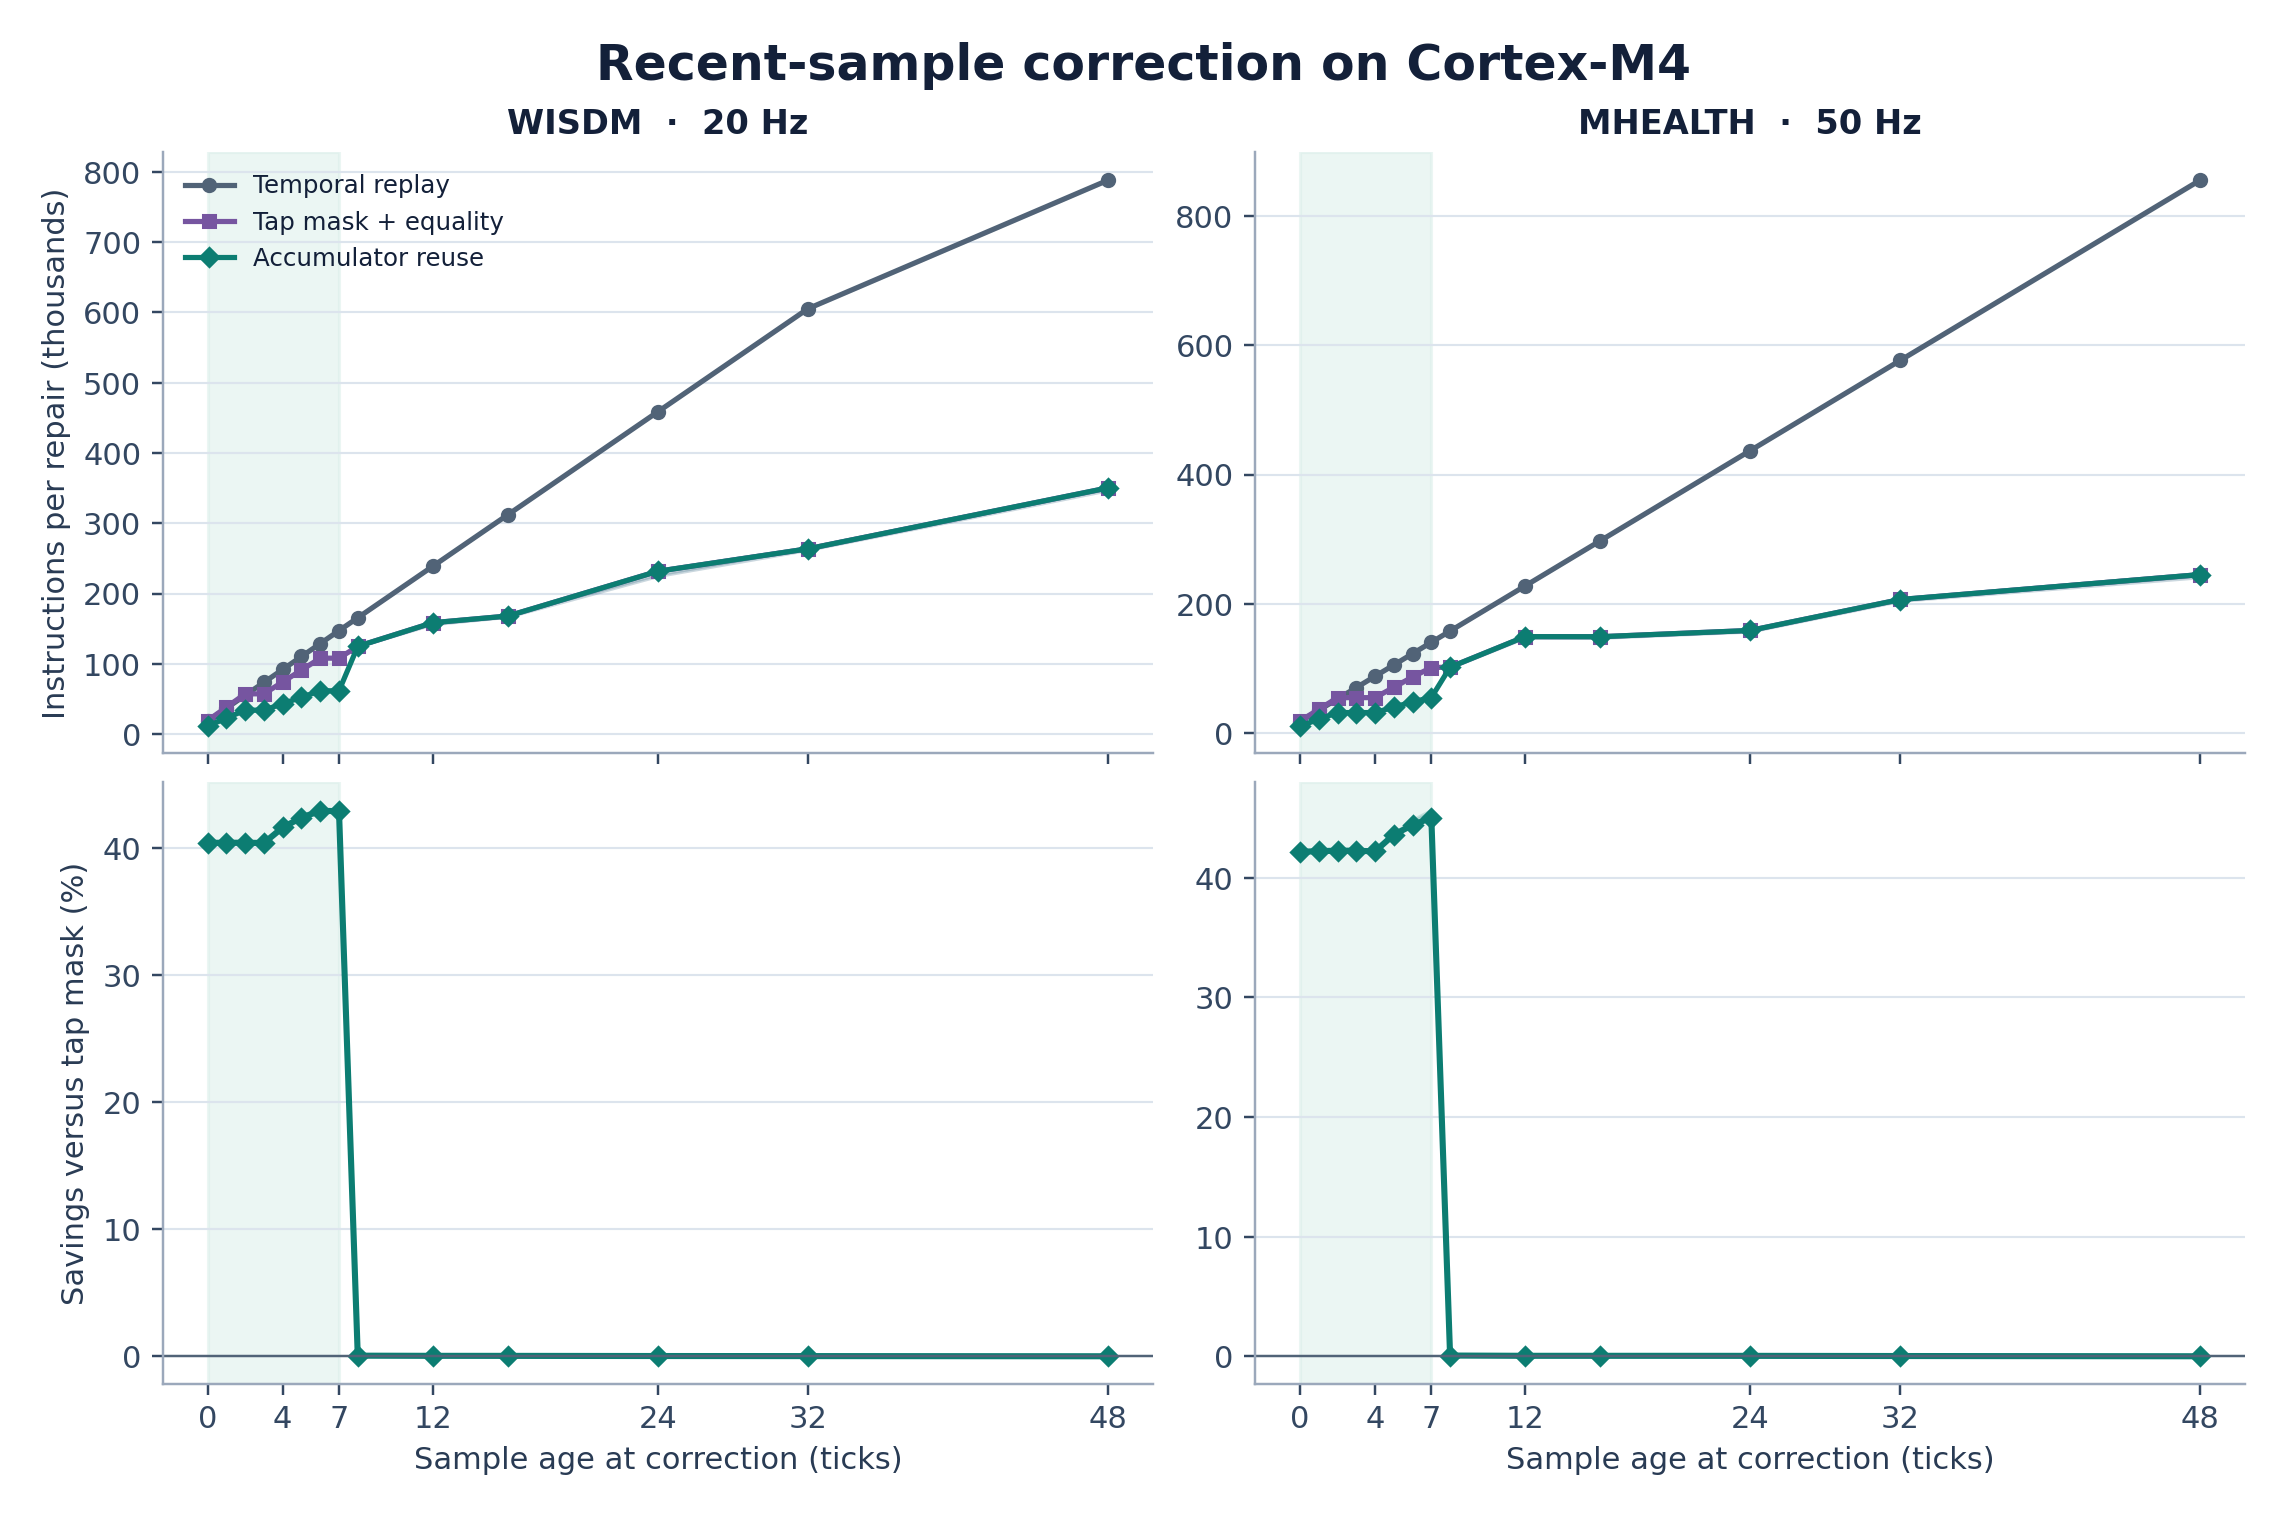

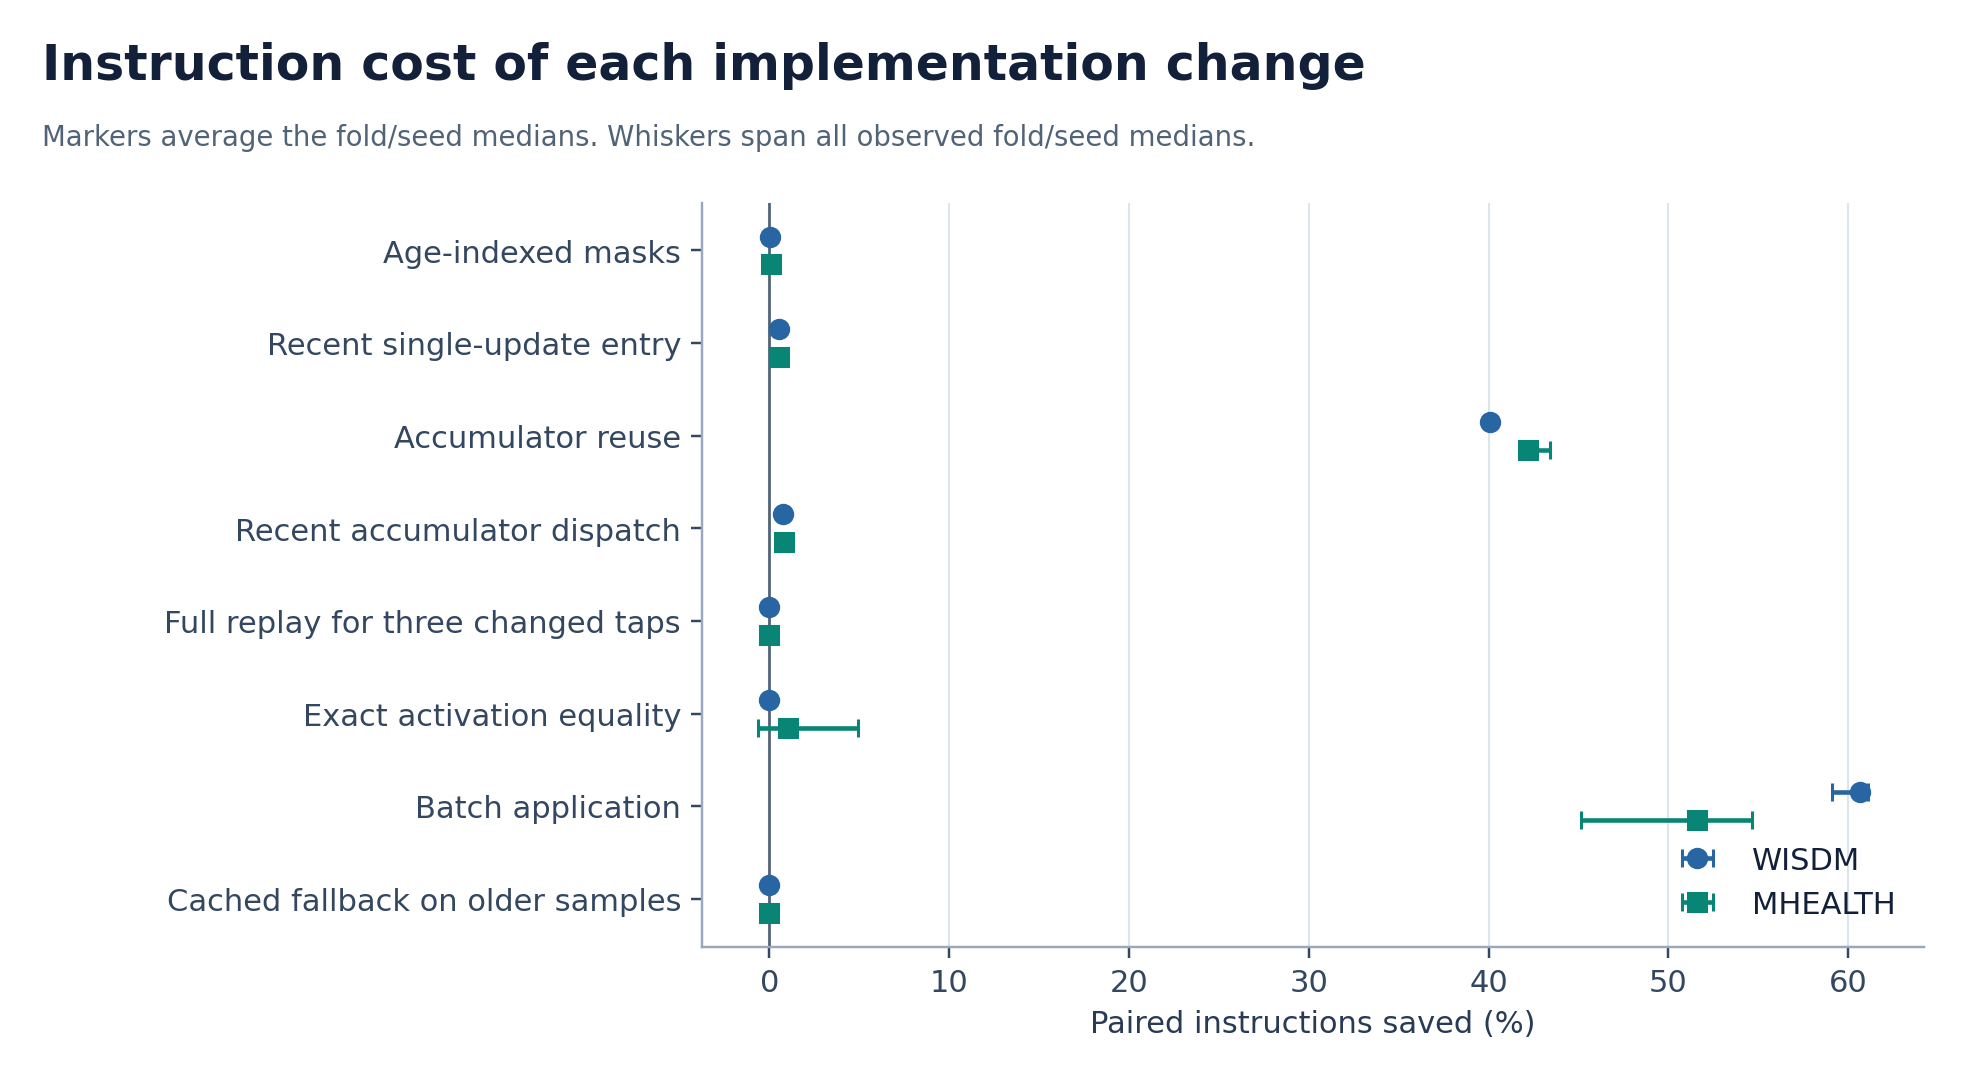

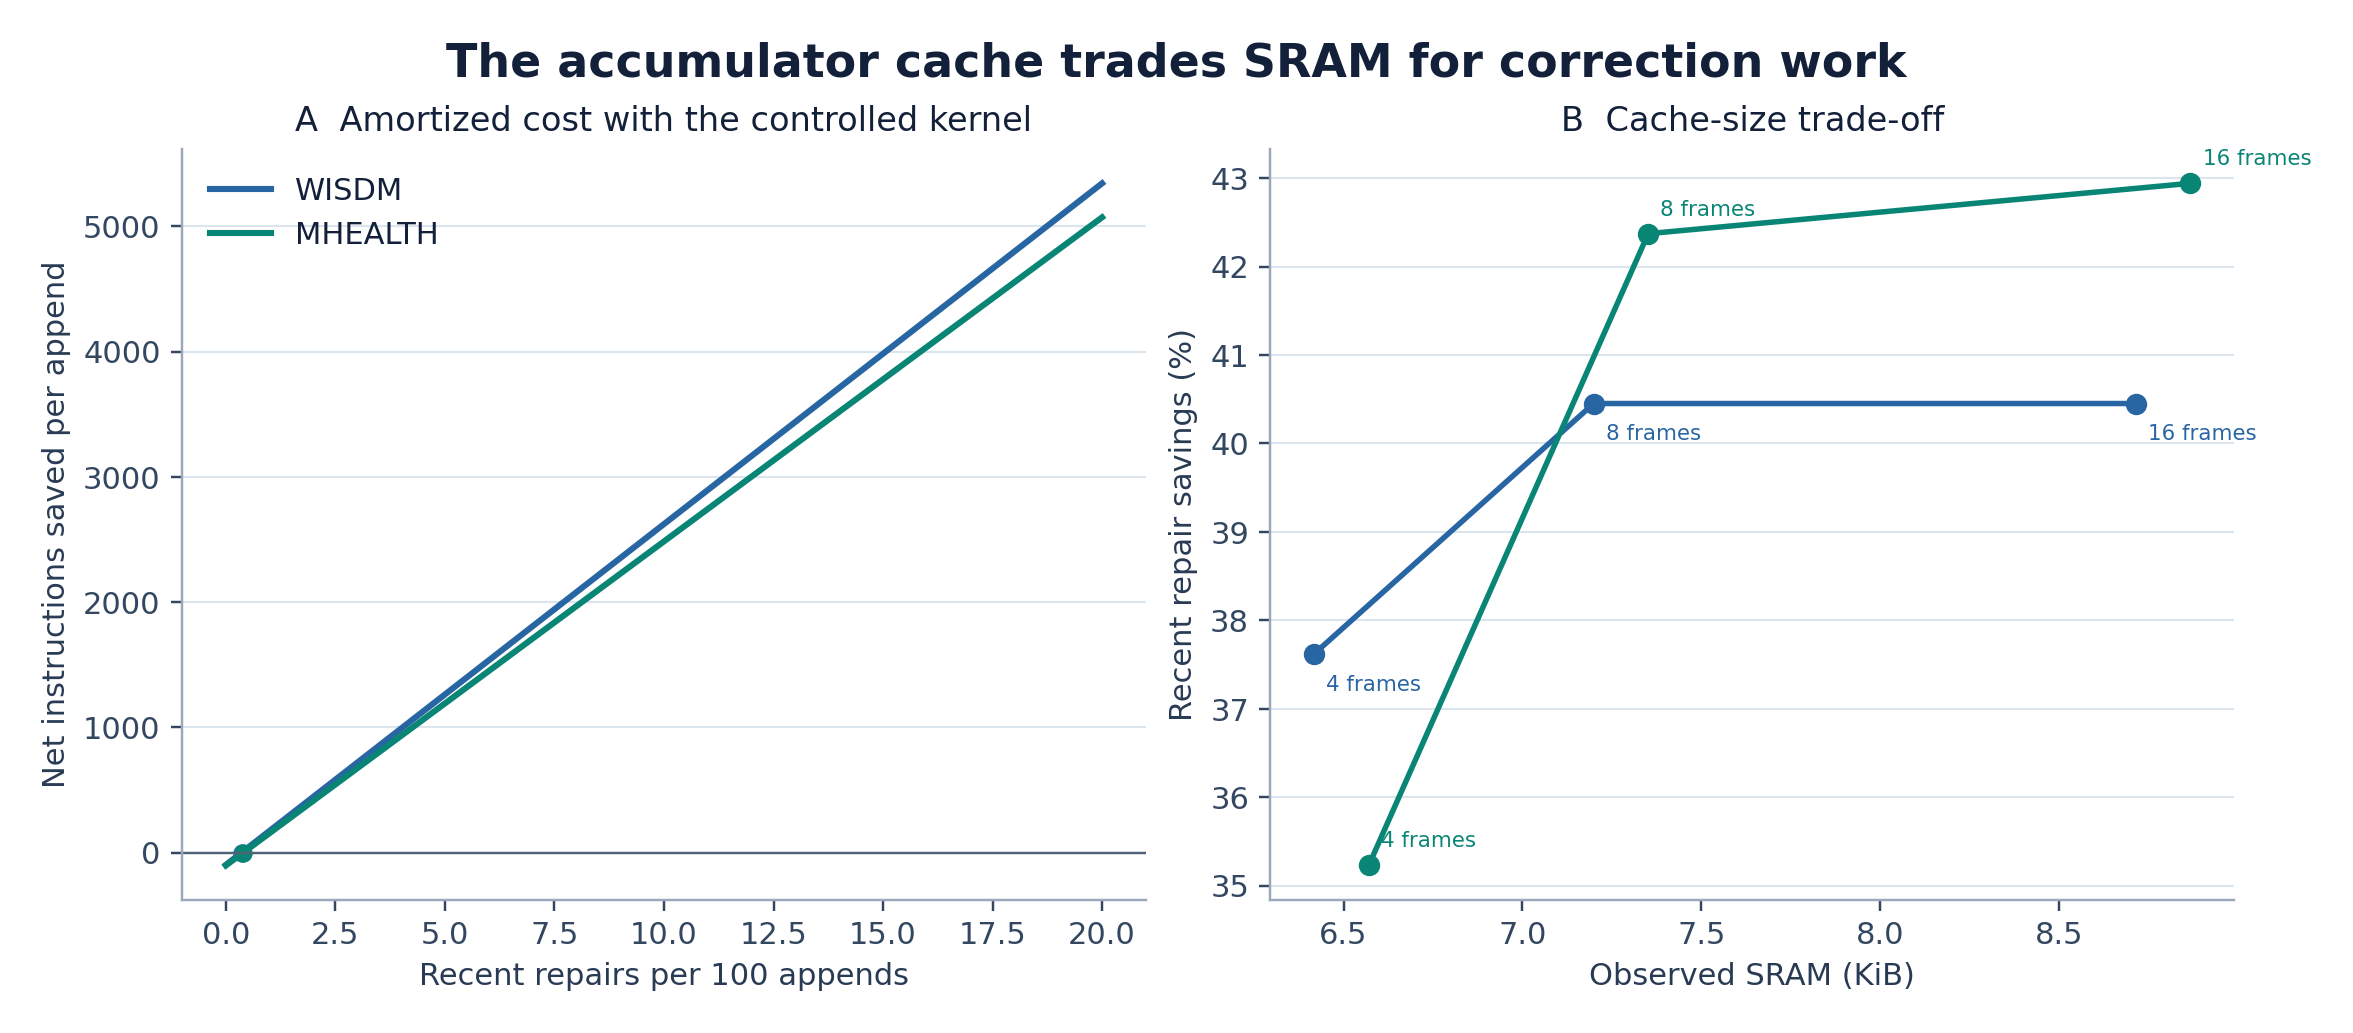

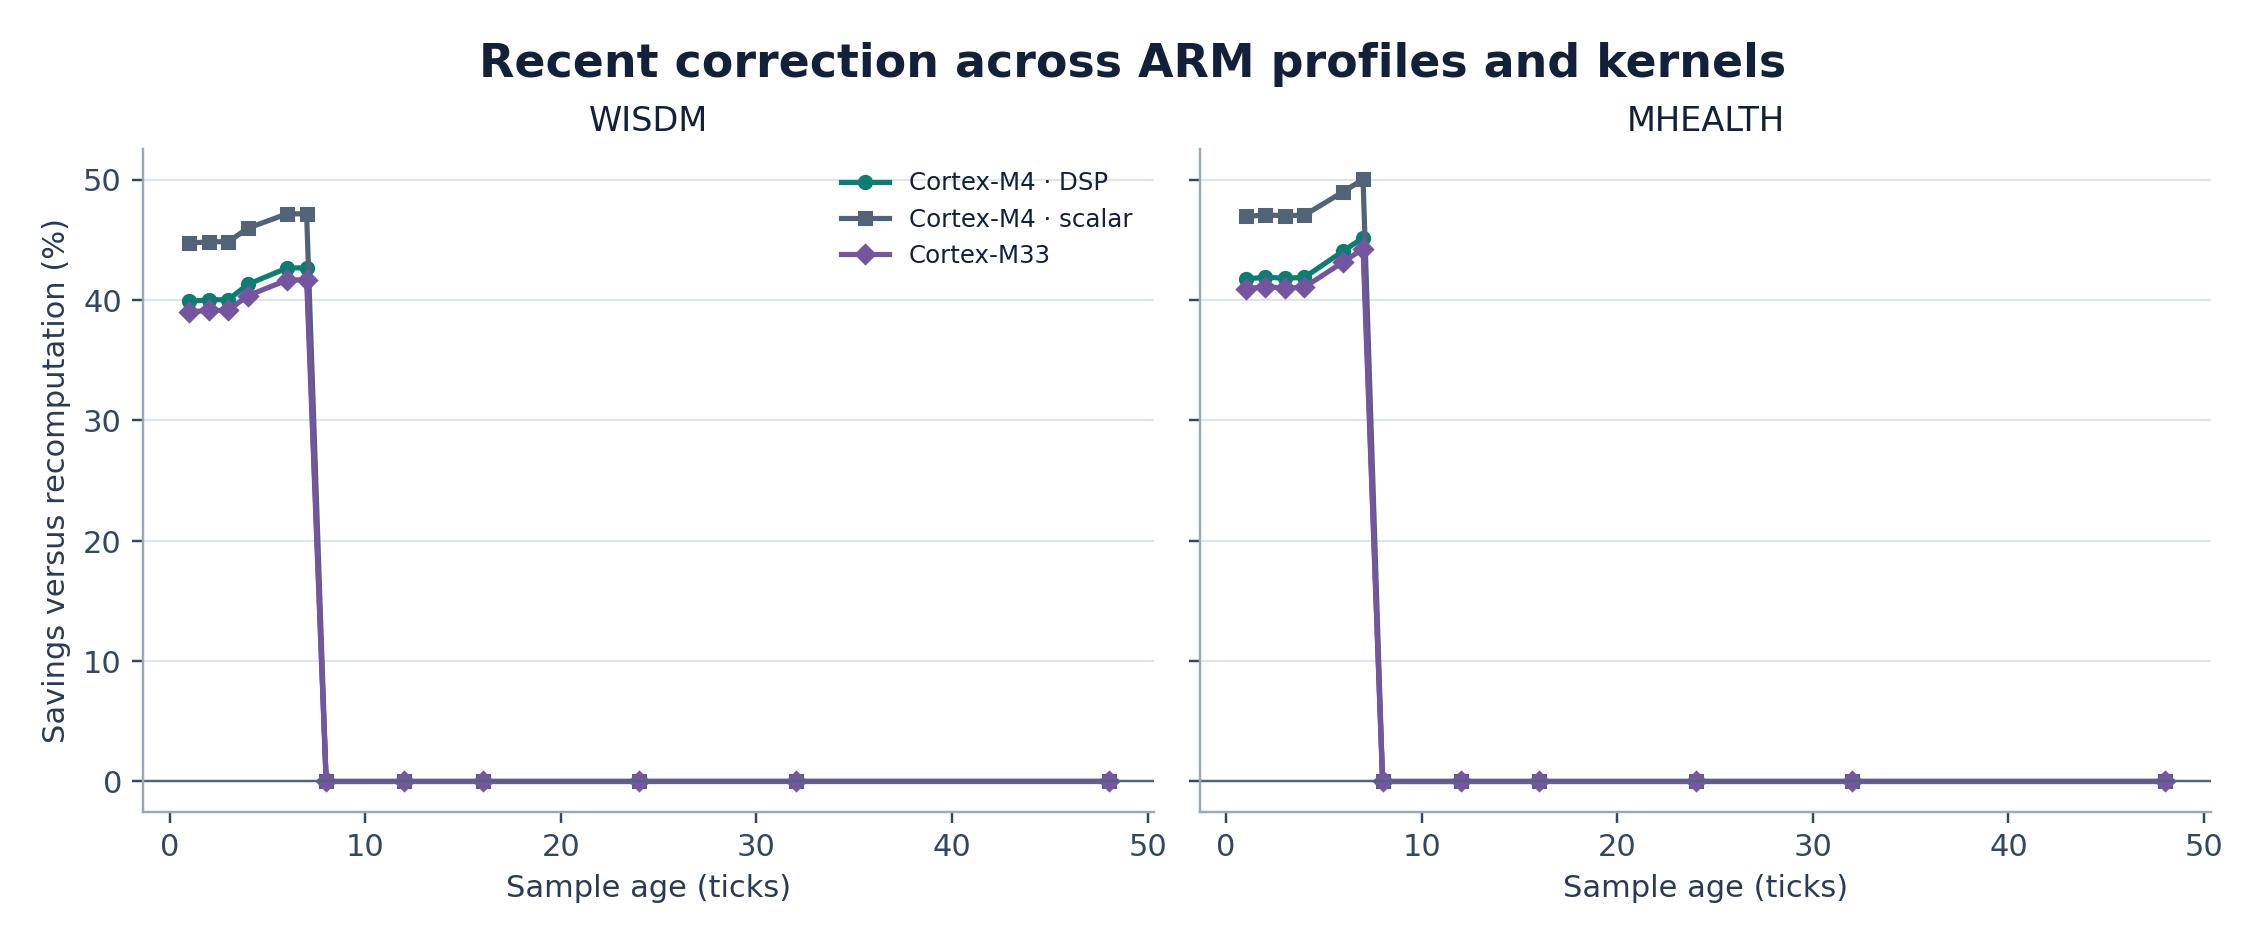

In [4]:
for prefix in ("fig_01_delay", "fig_02_ablation", "fig_03_resources", "fig_04_portability"):
    display(Image(filename=str(destination / f"{prefix}.png"), width=920, embed=True))